# Stimuli and scenarios

*Stimulus layer and task layer of `ActiveVisionBenchmark`.*

The study of active vision needs visual stimuli that are **controlled** and that respond to the movement of
the observer. Here a texture is projected onto a 3D geometry that is seen by a pinhole camera: a **tunnel**
(a textured cylinder) to simulate a confined environment, and an **infinite ground plane** to simulate
the navigation over a textured surface. When the camera moves, the texture slides on the surface and gives
the optic flow of an egomotion, with its **focus of expansion** (FoE).

This notebook describes the stimuli (section *Stimulus layer* of the paper), the projections (*Task layer*),
the ground-truth optic flow and the **passive** streams of images, and presents the four benchmarks AVB1 to AVB4 that
use them, and ends with the checks of the geometry and of the rendering speed.

## Contents

1. [The model](#The-model)
2. [Stimulus layer](#Stimulus-layer): the textures that the library draws
3. [Task layer: the projections](#Task-layer:-the-projections), with the [luminance attenuation](#Luminance-attenuation-with-the-distance)
4. [Ground-truth optic flow](#Ground-truth-optic-flow)
5. [Passive streams of images](#Passive-streams-of-images), with the videos of [every stimulus in motion](#Every-stimulus-in-motion)
6. [The four benchmarks](#The-four-benchmarks): AVB1 to AVB4, with the notebooks that run them
7. [Checks](#Checks), including the maximum frame rate of the rendering on the CPU and the GPU


## The model

A pixel is seen at the azimuth $u$ and at the elevation $v$ from the optical axis of the camera, which
points to the gaze $g$. The camera translates along the heading $h$, and the FoE is seen at the azimuth

$$u_\mathrm{FoE} = h - g .$$

**Tunnel.** For a cylinder of radius $R$, the angle of a pixel around the axis and its deviation from the
axis are

$$\theta = \arctan\frac{v}{u - u_\mathrm{FoE}}, \qquad
  \phi \approx \sqrt{(u - u_\mathrm{FoE})^2 + v^2},$$

(the exact great-circle distance is used if `exact=True`). The wall seen in that pixel is at the depth
$Z = R / \tan\phi$. The texture, of period $P$ along the axis, is sampled at
$\left(\theta/\pi,\ (Z + s) \bmod P\right)$ where $s$ is the distance travelled. The luminance of a
surface element decreases with its distance: the image is multiplied by $(Z_\mathrm{min}/Z)^{n}$, which is
the inverse-square law for $n=2$ (a headlight at the camera; an extended light such as neon tubes decays more slowly,
$n \approx 1$, and $n=0$ removes the attenuation). An optional circular mask (`mask=True`),
centred on the centre of the image and not on the FoE, removes the border.

**Plane.** The ground is the plane $Y=0$, and the camera is at the height $H$ with the pitch $p$. The ray
of a pixel has the direction $\mathbf d = (d_x, d_y, d_z)$ in the world; it hits the ground at
$t = H / (-d_y)$, at the point $(X, Z) = (X_c + t\,d_x,\ Z_c + t\,d_z)$ where the texture is sampled
with the period $P$ in both directions. The sky is black.

| Symbol | Name in the code | Default value | Role |
|--------|------------------|---------------|------|
| $VA$ | `visual_angle` | 45 deg | visual angle of the width of the image |
| $u, v$ | `Task._angles()` | $\pm VA/2$ | azimuth and elevation of a pixel (deg) |
| $g$ | `Pose.gaze` | 0 deg | azimuth of the optical axis in the world |
| $h$ | `Pose.heading` | 0 deg | azimuth of the direction of travel in the world |
| $R$ | `radius` | 1 m | radius of the tunnel |
| $P$ | `period` | 10 m | period of the texture (along the axis, or on the ground) |
| $s$ | `Pose.distance` | 0 m | distance travelled |
| $n$ | `depth_exponent` | 2 (0 landing) | exponent of the luminance attenuation with the distance |
| $H$ | `camera_height` | 1.5 m | height of the camera over the plane |
| $p$ | `pitch` | 0 deg | elevation of the optical axis (negative looks down) |
| $\Delta t$ | `dt` | 1/60 s | duration of a time step of the camera (its frame rate) |
| $k$ | `control_every` | 1 | camera steps between two decisions of the model: the step of the perception-action loop is $k\,\Delta t$ (`control_dt`) |
| | `speed` | 6 m/s (tunnel), 4 m/s (plane) | speed of the camera |

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().parent          # the repository, when the package is not installed
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

import ActiveVisionBenchmark as avb
from functools import partial

cached = partial(avb.cached, cache_dir=ROOT / "cache")
save = partial(avb.save_figure, directory=ROOT / "figures")

# Colour-blind safe palette (Okabe-Ito)
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#666666"

import dataclasses

import torch
import torch.nn.functional as F

SEED = 0

## Stimulus layer

A stimulus is an **object** that creates an image. Called with `stimulus(size, seed)`, it returns a texture
in [0, 1] that is deterministic for a given seed. Its parameters are in `stimulus.params`, which is what
the cache of a long computation uses as a key.

* `GridStimulus`: a regular grid, for baseline experiments and control displays.
* `MotionCloudStimulus`: band-pass noise with a controlled spatial-frequency content, a procedural texture
  with natural-like statistics but a parametric control.
* `GaussianNoiseStimulus`: white Gaussian noise.
* `BinaryNoiseStimulus`: white binary noise (two luminances, probability `p`).
* `DotNoiseStimulus`: sparse bright dots (`sparseness`, `dot_size`) on a dark background.
* `ImageStimulus`: any user image, such as a natural image from a dataset. Without a path it draws a periodic
  mosque tiling (4.8.8 with eight-pointed stars), turned by `angle` (22.62 deg by default, $\tan = 5/12$) and
  repeated `cells` times (13) along the width. The image stays periodic in both directions only for the angles of
  rational tangent, so `angle` and `cells` are replaced by the closest values that wrap around
  (`tiling_angle`, `tiling_cells`).
* `ArrayStimulus`: a texture that is already an array.

All of them are drawn below at the same size and seed (the grid, the tiling and the image do not depend on the seed).
The two Motion Clouds show how `sf_0` and `B_sf` control the spatial scale of the texture. The videos of the section
*Passive streams of images* show the same stimuli in motion.


[]

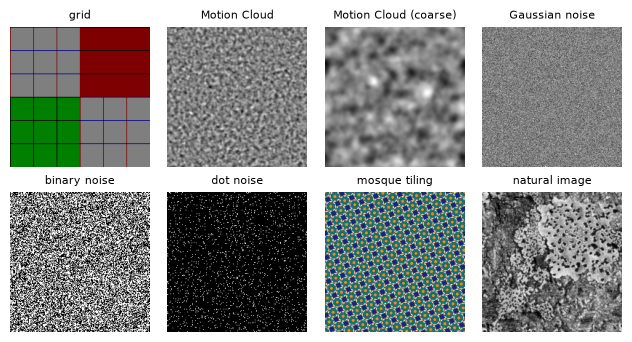

In [2]:
size = (192, 192)
stimuli = {
    "grid": avb.GridStimulus(32, colour=True),
    "Motion Cloud": avb.MotionCloudStimulus(),
    "Motion Cloud (coarse)": avb.MotionCloudStimulus(sf_0=0.03, B_sf=0.03),
    "Gaussian noise": avb.GaussianNoiseStimulus(),
    "binary noise": avb.BinaryNoiseStimulus(),
    "dot noise": avb.DotNoiseStimulus(sparseness=0.05, dot_size=2),
    "mosque tiling": avb.ImageStimulus(colour=True),
    # natural_image.jpeg: a lichen photograph (square crop, 1024 pixels), rolled by half a period so that the seams of the torus
    # form a central cross, healed by image quilting (best-matching blocks under the 8 symmetries of the square, minimum-error cuts, seed 0).
    "natural image": avb.ImageStimulus(ROOT / "notebooks" / "natural_image.jpeg"),
}
fig, axes = avb.new_figure(16, 8.4, 2, 4)
for ax, (name, stimulus) in zip(axes.flat, stimuli.items()):
    image = stimulus(size, SEED)
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None, vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")
save(fig, "01_stimuli")

The Motion Clouds are generated by the `MotionClouds` package when it is installed (an optional
dependency), and by a built-in implementation of the same log-Gabor envelope otherwise, so that the
single file also works alone. The two backends have the **same statistics but not the same pixels** for
a given seed; the backend that is actually used is recorded in `stimulus.params`. Their images and their
mean radial power spectra (over 20 seeds) agree:

[]

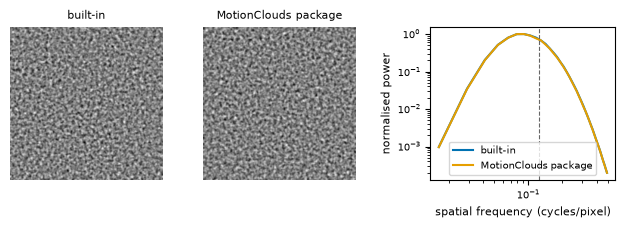

In [3]:
def radial_spectrum(images):
    """Mean radial power spectrum of a list of images."""
    power = np.mean([np.abs(np.fft.fftshift(np.fft.fft2(im - im.mean()))) ** 2 for im in images], axis=0)
    h, w = power.shape
    yy, xx = np.indices(power.shape)
    radius = np.hypot((xx - w // 2) / w, (yy - h // 2) / h)
    edges = np.linspace(0.01, 0.5, 40)
    which = np.digitize(radius.ravel(), edges)
    spectrum = np.array([power.ravel()[which == k].mean() for k in range(1, len(edges))])
    return 0.5 * (edges[1:] + edges[:-1]), spectrum

backends = {"built-in": avb.MotionCloudStimulus(backend="builtin")}
try:
    backends["MotionClouds package"] = avb.MotionCloudStimulus(backend="motionclouds")
    backends["MotionClouds package"]((16, 16), 0)
except ImportError:
    print("MotionClouds is not installed: only the built-in backend is shown.")

fig, axes = avb.new_figure(16, 5.5, 1, len(backends) + 1)
for ax, (name, stimulus) in zip(axes, backends.items()):
    ax.imshow(stimulus((256, 256), SEED), cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")
for (name, stimulus), color in zip(backends.items(), (BLUE, ORANGE)):
    f, spectrum = radial_spectrum([stimulus((256, 256), s) for s in range(20)])
    axes[-1].loglog(f, spectrum / spectrum.max(), color=color, label=name)
axes[-1].axvline(avb.MotionCloudStimulus().sf_0, color=GREY, ls="--", lw=0.8)
axes[-1].set_xlabel("spatial frequency (cycles/pixel)")
axes[-1].set_ylabel("normalised power")
axes[-1].xaxis.set_minor_formatter(plt.NullFormatter())
axes[-1].legend()
save(fig, "01_motion_cloud_backends")

## Task layer: the projections

A task takes a stimulus and projects it onto its geometry. `task.render(pose)` gives the image seen by a
camera at `pose`. Below, the same two textures are projected onto the tunnel, with the FoE at the
centre of the image or decentred by 8 degrees (the heading is 8 degrees away from the gaze), and onto the
ground plane.

[]

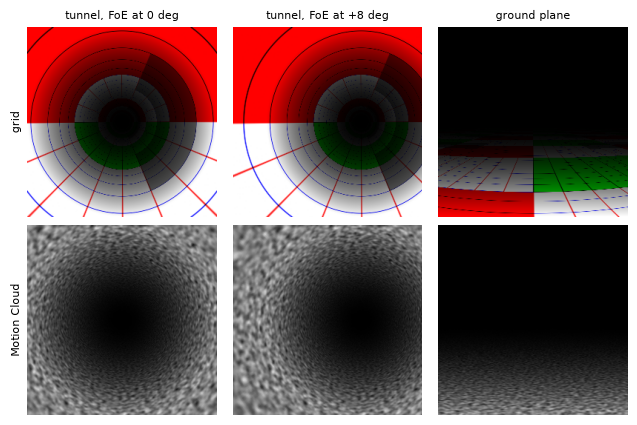

In [4]:
def to_image(tensor):
    array = tensor.cpu().numpy()
    return array[0] if array.shape[0] == 1 else np.moveaxis(array, 0, -1)

def show(ax, task, pose, title=None):
    image = to_image(task.render(pose, seed=SEED))
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    if title:
        ax.set_title(title)
    ax.axis("off")

textures = {"grid": avb.GridStimulus(32, colour=True), "Motion Cloud": avb.MotionCloudStimulus()}
fig, axes = avb.new_figure(16, 10.5, 2, 3)
for row, (name, stimulus) in zip(axes, textures.items()):
    tunnel = avb.CylinderTask(stimulus, size=256, texture_size=512)
    ground = avb.HorizontalPlaneTask(stimulus, size=256, texture_size=512)
    show(row[0], tunnel, avb.Pose(heading=0.0), "tunnel, FoE at 0 deg" if name == "grid" else None)
    show(row[1], tunnel, avb.Pose(heading=8.0), "tunnel, FoE at +8 deg" if name == "grid" else None)
    show(row[2], ground, avb.Pose(heading=8.0), "ground plane" if name == "grid" else None)
    row[0].text(-0.06, 0.5, name, rotation=90, transform=row[0].transAxes, ha="center", va="center")
save(fig, "01_geometries")

### Luminance attenuation with the distance

The attenuation $(Z_\mathrm{min}/Z)^n$ is the inverse-square law for $n = 2$: it is valid for a point light
that is at the camera (a headlight), for which the illumination of a Lambertian wall decreases as
$1/d^2$. For $n = 0$ there is no attenuation, as under an ambient light; $n = 1$ is a softer fall-off. The
exponent is a parameter, `depth_exponent`.

[]

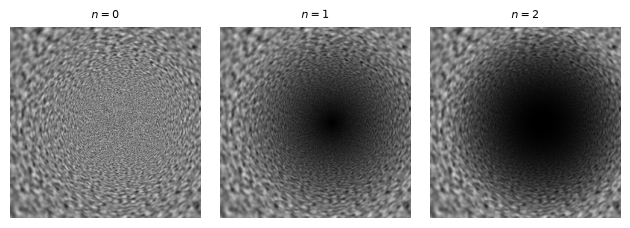

In [5]:
fig, axes = avb.new_figure(16, 5.5, 1, 3)
for ax, n in zip(axes, (0.0, 1.0, 2.0)):
    tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), size=256, texture_size=512, depth_exponent=n)
    show(ax, tunnel, avb.Pose(heading=4.0), f"$n = {n:g}$")
save(fig, "01_depth_exponent")

## Ground-truth optic flow

A task also gives the exact optic flow of a forward translation, `task.flow(pose)`: the displacement of
every pixel for one time step. The flow of a translation is **radial** and diverges from the FoE. The
arrows below are multiplied by 15 to be visible, as the displacement is of the order of a pixel per
frame.

[]

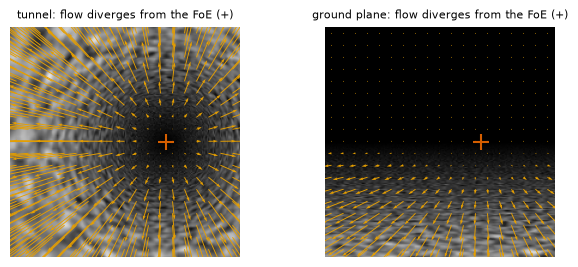

In [6]:
def quiver(ax, task, pose, title, step=10, gain=15):
    flow = task.flow(pose).cpu().numpy() * task.pixels_per_degree          # pixels per step
    image = to_image(task.render(pose, seed=SEED))
    h, w = flow.shape[1:]
    ys, xs = np.mgrid[step // 2:h:step, step // 2:w:step]
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.quiver(xs, ys, gain * flow[0][ys, xs], -gain * flow[1][ys, xs], angles="xy", scale_units="xy",
              scale=1, color=ORANGE, width=0.004)
    foe_column = (pose.foe / task.visual_angle + 0.5) * (w - 1)
    ax.plot(foe_column, (h - 1) / 2, "+", color=RED, ms=12, mew=1.5)
    ax.set_title(title)
    ax.axis("off")

tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), size=192, depth_exponent=1.0)
ground = avb.HorizontalPlaneTask(avb.MotionCloudStimulus(), size=192, depth_exponent=1.0)
fig, axes = avb.new_figure(16, 6.5, 1, 2)
quiver(axes[0], tunnel, avb.Pose(heading=8.0), "tunnel: flow diverges from the FoE (+)")
quiver(axes[1], ground, avb.Pose(heading=8.0), "ground plane: flow diverges from the FoE (+)")
save(fig, "01_flow")

## Passive streams of images

A **passive** benchmark generates a stream of frames while the camera follows its own course, with the ground
truth available at each frame. The offset between the gaze and the direction of travel is not constant: it follows the exogenous trajectory of the
`Perturbation` of the task, here a slow diffusion of time constant $\tau$ and amplitude $\sigma_\mathrm{OU}$
(the FoE, which is the target of the active benchmarks, wanders in the image).

[]

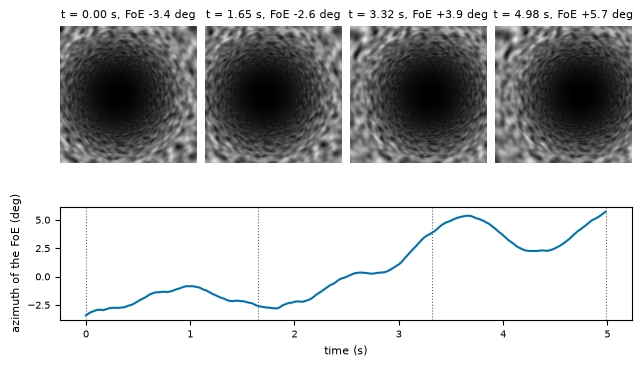

In [7]:
perturbation = avb.Perturbation(dt=1 / 60, tau=1.0, sigma_ou=5.0)
tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), size=256, perturbation=perturbation)
frames = list(avb.PassiveBenchmark(tunnel).stream(n_frames=avb.scaled(300, 20), seed=2))

shown = np.linspace(0, len(frames) - 1, 4).astype(int)
fig, axes = avb.new_figure(16, 9.5, 2, 4, height_ratios=[1, 0.55])
for ax, k in zip(axes[0], shown):
    ax.imshow(frames[k].image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {frames[k].t:.2f} s, FoE {frames[k].pose.foe:+.1f} deg")
    ax.axis("off")
gs = axes[1, 0].get_gridspec()
for ax in axes[1]:
    ax.remove()
ax = fig.add_subplot(gs[1, :])
ax.plot([f.t for f in frames], [f.pose.foe for f in frames], color=BLUE)
ax.set_xlabel("time (s)")
ax.set_ylabel("azimuth of the FoE (deg)")
for k in shown:
    ax.axvline(frames[k].t, color=GREY, ls=":", lw=0.8)
save(fig, "01_stream")

In [8]:
# Write the stream as a video (needs imageio and imageio-ffmpeg) and embed it in the notebook.
# One frame out of two is kept: the video is played at 30 images per second, in real time.
path = avb.save_video((frame.image for frame in frames[::2]), "01_tunnel", directory=ROOT / "figures", fps=30)
avb.show_video(path)

### Every stimulus in motion

The stimuli above are projected onto a tunnel, then onto the ground plane, with the same camera trajectory (same seed,
same slow diffusion of the heading). `avb.passive_video` writes one panel per task in `figures/` (128 pixels per panel,
a video of a few hundred kilobytes) and `avb.show_video` **embeds** it in the notebook, so that it is also shown by the
documentation. The regular patterns (grid, tiling) show the geometry, and the noises show that a texture without
structure still gives a flow, from the motion of its grain.

**Tunnel.** The camera travels along the axis and the texture expands from the focus of expansion, which wanders.

In [9]:
DURATION = avb.scaled(4, 1)                       # duration of the videos (s)
perturbation = avb.Perturbation(dt=1 / 60, tau=1.0, sigma_ou=3.0)

tunnels = {name: avb.CylinderTask(stimulus, size=128, perturbation=perturbation) for name, stimulus in stimuli.items()}
avb.show_video(avb.passive_video(tunnels, "01_stimuli_tunnel", directory=ROOT / "figures", duration=DURATION, seed=2, ncols=4))

**Ground plane.** The heading is decentred by 6 degrees from the gaze, so that the texture flows towards the side
of the horizon where the focus of expansion is.

In [10]:
planes = {name: avb.HorizontalPlaneTask(stimulus, size=128, perturbation=perturbation) for name, stimulus in stimuli.items()}
avb.show_video(avb.passive_video(planes, "01_stimuli_plane", directory=ROOT / "figures", duration=DURATION, seed=2, heading_offset=6.0, ncols=4))

## The four benchmarks

The tasks above are combined into four **benchmarks**, numbered AVB1 to AVB4. A benchmark is a task with its
parameters, a dataset of seeded trials, reference models and metrics, so that models of active vision can be
compared on the same footing. Each one has a **card** in the notebook that runs it, with its important parameters.

| Benchmark | Name | Task | Target | The model has to | Main metrics | Notebook |
|-----------|------|------|--------|------------------|--------------|----------|
| AVB1 | `plane` | `HorizontalPlaneTask` | FoE on the horizon of a ground plane, diffusing slowly | estimate the heading (passive) | RMS and median error (deg), $A$, $H$, $F$, $d'$ | [02](02_navigation_plane_cylinder.ipynb) |
| AVB2 | `cylinder` | `CylinderTask` | FoE in the image of a tunnel, diffusing slowly | keep the gaze on the axis (active) | RMS error of the FoE (deg) | [02](02_navigation_plane_cylinder.ipynb) |
| AVB3 | `perturb` | `CylinderTask` with jumps | AVB2, plus abrupt jumps of the FoE | resist the jumps and recover (active) | RMS error of the FoE (deg), recovery time (s) | [03](03_perturbation.ipynb) |
| AVB4 | `landing` | `LandingTask` | ground plane seen from above, expanding | land fast and softly (active) | success rate, time to land (s), speed at contact (m/s) | [04](04_landing.ipynb) |

The parameters of the cards are the ones that the notebooks use, and the cells below each card print them from the
task objects. Three values are **not harmonised** between the benchmarks, and they are left as they are because
the numbers of the results come from them:

* the master seed (42, 42, 7 and 3) and the number of trials (200, 24, 24 and 100 episodes);
* the noise of the images, `noise_std`, which is 0 for AVB1 and 0.01 for the three others;
* the length of a tunnel trial, which is 300 steps (5 s) in AVB2 and 900 steps (15 s) in AVB3.


## Checks

The checks of this notebook are visual or numerical comparisons with what the geometry predicts, and a measure of the
speed of the rendering.

**1. The texture is periodic.** Moving the camera by one period gives the same image: no seam appears when
the texture is rolled.

In [11]:
tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), size=128)
ground = avb.HorizontalPlaneTask(avb.MotionCloudStimulus(), size=128)

pose = avb.Pose(heading=3.0, gaze=1.0, distance=1.3, x=0.8, z=2.1)
for name, task, moved in [
    ("tunnel, s + P", tunnel, dataclasses.replace(pose, distance=pose.distance + tunnel.period)),
    ("plane, x + P", ground, dataclasses.replace(pose, x=pose.x + ground.period)),
    ("plane, z + P", ground, dataclasses.replace(pose, z=pose.z + ground.period)),
]:
    difference = (task.render(pose, seed=1) - task.render(moved, seed=1)).abs().max().item()
    print(f"{name:14s} max |I(shifted) - I| = {difference:.1e}")

tunnel, s + P  max |I(shifted) - I| = 0.0e+00
plane, x + P   max |I(shifted) - I| = 0.0e+00
plane, z + P   max |I(shifted) - I| = 0.0e+00


**2. Everything is reproducible.** The same seed gives the same stimulus and the same trials.

In [12]:
stimulus = avb.MotionCloudStimulus()
print("same seed, same texture:      ", np.array_equal(stimulus((64, 64), 3), stimulus((64, 64), 3)))
print("other seed, other texture:    ", not np.array_equal(stimulus((64, 64), 3), stimulus((64, 64), 4)))
print("same master seed, same trials:", ground.generate_dataset(5, seed=0) == ground.generate_dataset(5, seed=0))

same seed, same texture:       True
other seed, other texture:     True
same master seed, same trials: True


**3. The ground-truth flow moves the pixels.** If the flow is right, the image of the next step, sampled
back along the flow, equals the current image. The residual of the warped image is much smaller than the
difference between the two frames. This is checked with a smooth texture and without attenuation, so that the
test isolates the geometry, and where the texture is well resolved (away from the FoE of the tunnel and
from the horizon of the plane, where the texture is extremely compressed).

tunnel  residual after warping / difference between frames = 0.025
plane   residual after warping / difference between frames = 0.103


[]

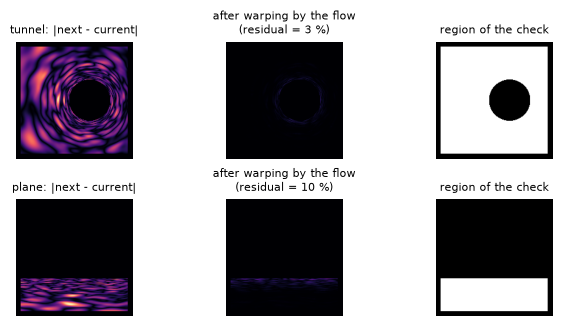

In [13]:
def warp_check(task, pose, moved, ds, region):
    first = task.render(pose, seed=0)[0]
    second = task.render(moved)[0]
    flow = task.flow(pose, ds) * task.pixels_per_degree
    h, w = first.shape
    rows, columns = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    grid = torch.stack((2 * (columns + flow[0]) / (w - 1) - 1, 2 * (rows - flow[1]) / (h - 1) - 1), -1)[None].float()
    warped = F.grid_sample(second[None, None], grid, align_corners=True, padding_mode="border")[0, 0]
    mask = region(task, pose)
    mask[:8] = mask[-8:] = False
    mask[:, :8] = mask[:, -8:] = False
    return (second - first).abs() * mask, (warped - first).abs() * mask, mask

smooth = avb.MotionCloudStimulus(sf_0=0.02, B_sf=0.02)
tunnel = avb.CylinderTask(smooth, size=192, depth_exponent=0.0, mask=False, device="cpu")
ground = avb.HorizontalPlaneTask(smooth, size=192, depth_exponent=0.0, device="cpu")
step = 0.1                                   # distance travelled between the two frames (m)
heading = np.radians(6.0)
cases = {
    "tunnel": (tunnel, avb.Pose(heading=6.0), avb.Pose(heading=6.0, distance=step),
               lambda task, pose: torch.hypot(task._angles()[0] - pose.foe, task._angles()[1]) > 8),
    "plane": (ground, avb.Pose(heading=6.0, gaze=1.0),
              avb.Pose(heading=6.0, gaze=1.0, distance=step, x=step * np.sin(heading), z=step * np.cos(heading)),
              lambda task, pose: task._angles()[1] < -8),
}

fig, axes = avb.new_figure(16, 8, 2, 3)
for row, (name, (task, pose, moved, region)) in zip(axes, cases.items()):
    before, after, mask = warp_check(task, pose, moved, step, region)
    ratio = (after.sum() / before.sum()).item()
    vmax = before.max().item()
    row[0].imshow(before, cmap="magma", vmin=0, vmax=vmax); row[0].set_title(f"{name}: |next - current|")
    row[1].imshow(after, cmap="magma", vmin=0, vmax=vmax); row[1].set_title(f"after warping by the flow\n(residual = {100 * ratio:.0f} %)")
    row[2].imshow(mask, cmap="gray"); row[2].set_title("region of the check")
    for ax in row:
        ax.axis("off")
    print(f"{name:7s} residual after warping / difference between frames = {ratio:.3f}")
save(fig, "01_checks_flow")

**4. The target is where the flow is null.** For a trial of the plane task, the pixel `target_location` is
the position of the FoE. The horizontal ground-truth flow of the lower half of the image vanishes in that column.

[]

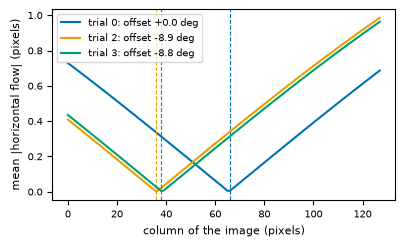

In [14]:
ground = avb.HorizontalPlaneTask(avb.MotionCloudStimulus(), size=128)
fig, ax = avb.new_figure(10, 6)
for seed, color in zip((0, 2, 3), (BLUE, ORANGE, GREEN)):
    trial = ground.generate_trial(seed)
    ground.reset(trial)
    profile = ground.flow(ground.pose)[0, 80:].abs().mean(0).cpu().numpy() * ground.pixels_per_degree
    ax.plot(profile, color=color, label=f"trial {seed}: offset {trial.heading_offset:+.1f} deg")
    ax.axvline(trial.target_location[1], color=color, ls="--", lw=0.8)
ax.set_xlabel("column of the image (pixels)")
ax.set_ylabel("mean |horizontal flow| (pixels)")
ax.legend()
save(fig, "01_checks_target")

**5. How fast are the images generated on the fly?** The maximum frame rate is the inverse of the time that
`task.render(pose)` takes to draw an image, for a camera that moves at every frame (a new pose each time, so that nothing
is reused). It is measured as a function of the image size, for the tunnel and for the plane, on the CPU and on the
GPU (`mps`). Two uses are distinguished on the GPU:

* **read back**: every image is copied to the CPU (`.cpu().numpy()`), as `PassiveBenchmark.stream` does to write a video;
  this is also what a model that runs on the CPU needs at every step of the loop;
* **on device**: the images stay on the GPU, as for a model that runs there. The frames are then queued and the GPU is
  synchronised once per block, which hides the latency of each launch.

The reference of the default camera is $1/\Delta t = 60$ images per second, the real time of a video. The times are those
of this machine, and they are cached (`recompute=True` measures them again). They are only meaningful when nothing else
uses the GPU or the cores during the measure.

The measure also gives the **size beyond which the GPU is faster than the CPU**: the crossing of the two curves,
interpolated in log-log. It is the value that `Task` should use to choose its device (the red line of the figure marks
the side at which it switches now, 192 pixels). It is a limit for the rendering alone: a model whose estimators
synchronise the GPU at every step moves it towards larger images.

tunnel: maximum frame rate (images/s)
  pixels                     CPU    GPU (mps), read back    GPU (mps), on device
      32                   16614                    2488                    5698
      64                    2937                    2495                    6003
     128                    1913                    2427                    5925
     192                     271                    2335                    5367
     256                     262                    2384                    5271
     384                     246                    2167                    4166
     512                     219                    2057                    3767
     768                     173                    1683                    2865
    1024                     132                    1347                    2087
    1536                      75                     805                    1128
    2048                      47                     402               

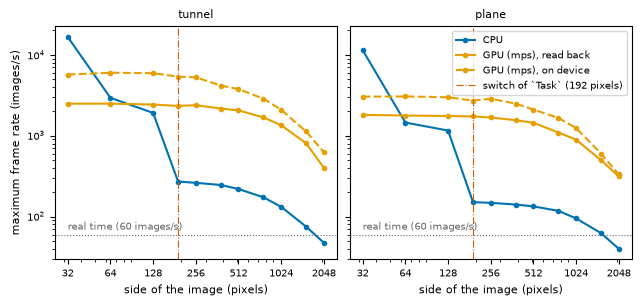

In [15]:
import platform
import time

def measure_fps(task_class, size, device, read_back, n_frames, repeats):
    """Maximum frame rate (images/s) of `task.render`, as the median over `repeats` blocks of `n_frames` images."""
    task = task_class(avb.MotionCloudStimulus(), size=size, texture_size=512, device=device)
    task.prepare(SEED)
    pose = avb.Pose(heading=4.0)

    def block():
        start = time.perf_counter()
        for k in range(n_frames):
            image = task.render(dataclasses.replace(pose, distance=0.01 * k))      # the camera moves at every frame
            if read_back:
                image.cpu().numpy()
        if device == "mps":
            torch.mps.synchronize()                    # the GPU runs asynchronously: wait for the last image
        return (time.perf_counter() - start) / n_frames

    block()                                            # warm-up: Metal kernels, memory allocator
    return 1 / np.median([block() for _ in range(repeats)])

def crossover(sizes, cpu, gpu):
    """Side of the image (pixels) beyond which the GPU stays faster than the CPU, interpolated in log-log.

    The last size where the CPU wins counts, because the small sizes are noisy. It is 0 when the GPU is always faster
    and `inf` when it never is."""
    ratio = np.log(np.asarray(gpu) / np.asarray(cpu))
    cpu_wins = np.flatnonzero(ratio < 0)
    if len(cpu_wins) == 0:
        return 0.0
    i = cpu_wins[-1]
    if i == len(sizes) - 1:
        return np.inf
    t = -ratio[i] / (ratio[i + 1] - ratio[i])
    return float(np.exp(np.log(sizes[i]) + t * (np.log(sizes[i + 1]) - np.log(sizes[i]))))

SIZES = [32, 64, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048]     # side of the square images (pixels)
REPEATS = avb.scaled(5, 2)
REAL_TIME = 60                                                       # 1 / dt of the default camera (images/s)
TASK_SIDE = 192                                                      # side from which `Task` computes on the GPU (pixels)
MODES = {"CPU": ("cpu", True)}
if torch.backends.mps.is_available():
    MODES.update({"GPU (mps), read back": ("mps", True), "GPU (mps), on device": ("mps", False)})
else:
    print("mps is not available: only the CPU is measured.")
tasks = {"tunnel": avb.CylinderTask, "plane": avb.HorizontalPlaneTask}

def run_fps():
    return {
        (name, mode): [measure_fps(task_class, size, device, read_back, avb.scaled(200 if size <= 256 else 50, 5), REPEATS)
                       for size in SIZES]
        for name, task_class in tasks.items() for mode, (device, read_back) in MODES.items()
    }

fps = cached("render_fps", {"sizes": SIZES, "repeats": REPEATS, "modes": MODES, "texture_size": 512, "debug": avb.DEBUG,
                            "torch": torch.__version__, "machine": platform.platform(), "threads": torch.get_num_threads()},
             run_fps)

fig, axes = avb.new_figure(16, 7.5, 1, 2, sharey=True)
styles = {"CPU": (BLUE, "-"), "GPU (mps), read back": (ORANGE, "-"), "GPU (mps), on device": (ORANGE, "--")}
for ax, name in zip(axes, tasks):
    for mode in MODES:
        color, ls = styles[mode]
        ax.loglog(SIZES, fps[name, mode], "o", ls=ls, color=color, ms=3, label=mode)
    ax.axhline(REAL_TIME, color=GREY, ls=":", lw=0.8)
    ax.text(SIZES[0], REAL_TIME * 1.15, f"real time ({REAL_TIME} images/s)", color=GREY, fontsize=7)
    ax.axvline(TASK_SIDE, color=RED, ls="-.", lw=0.8, label=f"switch of `Task` ({TASK_SIDE} pixels)")
    ax.set_title(name)
    ax.set_xlabel("side of the image (pixels)")
    ax.set_xticks([32, 64, 128, 256, 512, 1024, 2048], [32, 64, 128, 256, 512, 1024, 2048])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("maximum frame rate (images/s)")
axes[1].legend(loc="upper right")
save(fig, "01_checks_fps")

for name in tasks:
    print(f"{name}: maximum frame rate (images/s)")
    print(f"{'pixels':>8s}" + "".join(f"{mode:>24s}" for mode in MODES))
    for i, size in enumerate(SIZES):
        print(f"{size:8d}" + "".join(f"{fps[name, mode][i]:24.0f}" for mode in MODES))

print(f"\nSide of the image beyond which the GPU is faster than the CPU (`Task` switches at {TASK_SIDE} pixels):")
for name in tasks:
    for mode in MODES:
        if mode != "CPU":
            side = crossover(SIZES, fps[name, "CPU"], fps[name, mode])
            print(f"  {name:7s} {mode:22s} {side:6.0f} pixels")